# NB5d — เทียบข้อมูลเข้าบนโปรโตคอลเดียวกัน

**คำถาม** ส่วนต่างของคะแนนระหว่าง NB5a กับ NB5c มาจาก *ข้อมูลเข้า* หรือ *โมเดล*

| ตรึงไว้ | ค่า |
|---|---|
| โจทย์หลัก | ไฟล์เดียว ตอบก่อน/หลัง |
| หน่วยให้คะแนน | ระดับไฟล์ |
| ข้อมูล | ไฟล์หลับตาที่ทั้งสองฝั่งมีครบ |
| fold | สร้างครั้งเดียวที่ระดับไฟล์ แบ่งตามคน ใช้ชุดเดิมทุกช่อง |
| ตัวชี้วัด | F1 เฉลี่ย 5 fold ± sd |

เปลี่ยนสองแกน — **ข้อมูลเข้า** FOOOF 24 ตัว / สเปกตรัมเต็ม / รูปคลื่นดิบ
และ **โมเดล** LR / RF / MLP / CNN

**การเลือกจำนวน epoch** ทุกโครงข่ายแบ่ง validation ออกจากชุดฝึกของแต่ละ fold
โดยแบ่งตามคน แล้วเลือก epoch ที่ validation ดีที่สุด ส่วนค่าตั้งอื่นของ CNN บนสเปกตรัม
(lr, batch, dropout) มาจากรอบแรกที่ปรับหลังเห็นว่าโมเดลทายคลาสเดียว ·
CNN บนรูปคลื่นใช้สถาปัตยกรรมเดิมจาก NB5a

**CNN บน FOOOF 24 ตัวไม่ทำ** เพราะ convolution ต้องการข้อมูลที่มีลำดับ
แต่ 24 ฟีเจอร์สลับที่กันได้อิสระ ผลจะขึ้นกับการเรียงคอลัมน์ ช่องนั้นใช้ MLP แทน

In [1]:
import os, glob, time, copy, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import welch
from sklearn.model_selection import GroupKFold
warnings.filterwarnings('ignore')
os.makedirs('outputs', exist_ok=True)

SF    = 128
REG   = ['frontal', 'central', 'occipital']
REGSL = {'frontal': slice(0, 7), 'central': slice(7, 14), 'occipital': slice(14, 20)}
MEAS  = ['low_alpha_corr', 'high_alpha_corr', 'low_alpha_rel', 'high_alpha_rel',
         'low_alpha_corr_rel', 'high_alpha_corr_rel', 'ap_exponent', 'ap_offset']
BASE  = 0.590                      # band power เฉลี่ยทั้งหัว โจทย์ไฟล์เดียว (NB4)

X  = np.load('outputs/cnn_X.npy')
md = pd.read_csv('outputs/cnn_meta.csv')
f4 = pd.read_csv('outputs/fooof_features_v4.csv')
print(f"หน้าต่าง {X.shape} · ไฟล์ {md.recording.nunique()} · คน {md.subject.nunique()}")

# ── ① FOOOF 24 ตัว ระดับไฟล์ ──
f4 = f4[(f4.task == 'EyesClosed') & (f4.ap_exponent > 0)].copy()
W  = f4.pivot_table(index=['subject', 'condition'], columns='region', values=MEAS)
W.columns = [f'{m}_{r}' for m, r in W.columns]
W = W.reset_index()
W['recording'] = W.subject + '_' + W.condition
FCOL = [f'{m}_{r}' for m in MEAS for r in REG]
W = W.dropna(subset=FCOL)

# ── ② สเปกตรัมระดับไฟล์ จากหน้าต่างชุดเดียวกับ CNN ──
fr, _ = welch(X[:1], fs=SF, nperseg=SF * 2, axis=2)
mfr   = (fr >= 1) & (fr <= 45)
FREQ  = fr[mfr]
recs  = np.sort(md.recording.unique())
ridx  = {r: i for i, r in enumerate(recs)}
acc   = np.zeros((len(recs), 20, mfr.sum()))
cnt   = np.zeros(len(recs))
for s in range(0, len(X), 4000):
    _, P = welch(X[s:s+4000], fs=SF, nperseg=SF * 2, axis=2)
    P = P[:, :, mfr]
    for j, r in enumerate(md.recording.values[s:s+4000]):
        acc[ridx[r]] += P[j]; cnt[ridx[r]] += 1
LOG_REC = np.log(acc / cnt[:, None, None]).astype(np.float32)
print(f"สเปกตรัม {LOG_REC.shape} ({mfr.sum()} bin ละ {FREQ[1]-FREQ[0]:.2f} Hz)")

# ── ③ ไฟล์ที่ทั้งสองฝั่งมีครบ ──
COMMON  = sorted(set(W.recording) & set(recs))
Wc      = W.set_index('recording').loc[COMMON]
F_FOOOF = Wc[FCOL].values.astype(np.float32)
F_SPEC  = np.stack([LOG_REC[ridx[r]] for r in COMMON])
Y_REC   = (Wc.condition == 'post').astype(int).values
G_REC   = Wc.subject.values
print(f"ใช้ร่วมกัน {len(COMMON)} ไฟล์ จาก {len(set(G_REC))} คน · "
      f"post {Y_REC.sum()} / pre {(1-Y_REC).sum()}")

# ── ④ fold ร่วม ──
FOLDS    = list(GroupKFold(5).split(F_FOOOF, Y_REC, groups=G_REC))
FOLD_REC = np.empty(len(COMMON), dtype=int)
for k, (_, te) in enumerate(FOLDS): FOLD_REC[te] = k
rec2fold = dict(zip(COMMON, FOLD_REC))
assert all(set(G_REC[tr]).isdisjoint(G_REC[te]) for tr, te in FOLDS), "คนรั่วข้าม fold"

# ── ⑤ หน้าต่างสำหรับฝั่งรูปคลื่น ──
keep  = md.recording.isin(COMMON).values
Xw    = np.ascontiguousarray(X[keep])
mdw   = md[keep].reset_index(drop=True)
Yw    = (mdw.condition == 'post').astype(np.float32).values
FOLDW = mdw.recording.map(rec2fold).values
GW    = mdw.subject.values
RECW  = mdw.recording.values
del X
print(f"หน้าต่างที่ใช้ {Xw.shape} · fold ผูกกับระดับไฟล์แล้ว")

หน้าต่าง (28942, 20, 512) · ไฟล์ 1211 · คน 608
สเปกตรัม (1211, 20, 89) (89 bin ละ 0.50 Hz)
ใช้ร่วมกัน 1209 ไฟล์ จาก 608 คน · post 606 / pre 603
หน้าต่างที่ใช้ (28894, 20, 512) · fold ผูกกับระดับไฟล์แล้ว


In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import f1_score

STRIDE = 1        # ← ใส่ 2 ถ้า RAM ไม่พอตอนทำฝั่งรูปคลื่น

MK = {
 'LR' : lambda: Pipeline([('sc', StandardScaler()),
                          ('clf', LogisticRegression(max_iter=3000, C=0.1))]),
 'RF' : lambda: RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                       max_features='sqrt', random_state=42, n_jobs=-1),
 'MLP': lambda: Pipeline([('sc', StandardScaler()),
                          ('clf', MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3,
                                                max_iter=2000, early_stopping=True,
                                                n_iter_no_change=20, validation_fraction=0.15,
                                                random_state=42))]),
}
ROWS, PROBA = [], {}          # PROBA เก็บความน่าจะเป็นนอก fold ไว้ใช้โจทย์จับคู่

def eval_rec(F, inp, mdl):
    """ฝึกและทำนายที่ระดับไฟล์"""
    p = np.zeros(len(F)); sc = []
    for tr, te in FOLDS:
        m = clone(MK[mdl]()).fit(F[tr], Y_REC[tr])
        p[te] = m.predict_proba(F[te])[:, 1]
        sc.append(f1_score(Y_REC[te], (p[te] > 0.5).astype(int)))
    PROBA[(inp, mdl)] = p
    ROWS.append({'input': inp, 'model': mdl, 'n_feat': F.shape[1],
                 'f1': float(np.mean(sc)), 'sd': float(np.std(sc)), 'folds': sc})
    print(f"  {inp:<14} {mdl:<4} F1 = {np.mean(sc):.3f} ± {np.std(sc):.3f}  ({F.shape[1]} ฟีเจอร์)")

def eval_win(inp, mdl):
    """ฝึกระดับหน้าต่าง รวมคำทำนายเป็นระดับไฟล์"""
    Fw = Xw[:, :, ::STRIDE].reshape(len(Xw), -1)
    pr = np.zeros(len(COMMON)); sc = []; t0 = time.time()
    for k in range(5):
        tr, te = FOLDW != k, FOLDW == k
        pw = clone(MK[mdl]()).fit(Fw[tr], Yw[tr]).predict_proba(Fw[te])[:, 1]
        agg = pd.DataFrame({'recording': RECW[te], 'p': pw}).groupby('recording').p.mean()
        for r, v in agg.items(): pr[COMMON.index(r)] = v
        yt = Y_REC[FOLD_REC == k]
        sc.append(f1_score(yt, (pr[FOLD_REC == k] > 0.5).astype(int)))
    PROBA[(inp, mdl)] = pr
    ROWS.append({'input': inp, 'model': mdl, 'n_feat': Fw.shape[1],
                 'f1': float(np.mean(sc)), 'sd': float(np.std(sc)), 'folds': sc})
    print(f"  {inp:<14} {mdl:<4} F1 = {np.mean(sc):.3f} ± {np.std(sc):.3f}"
          f"  ({Fw.shape[1]} ฟีเจอร์ · {time.time()-t0:.0f}s)")

print("① FOOOF 24 ตัว")
for m in ['LR', 'RF', 'MLP']: eval_rec(F_FOOOF, 'FOOOF', m)
print("\n② สเปกตรัมเต็ม")
for m in ['LR', 'RF', 'MLP']: eval_rec(F_SPEC.reshape(len(F_SPEC), -1), 'Spectrum', m)
print("\n③ รูปคลื่นดิบ — คาดไว้ล่วงหน้าว่าโมเดลตารางจะต่ำ")
for m in ['LR', 'RF']: eval_win('Raw', m)

① FOOOF 24 ตัว
  FOOOF          LR   F1 = 0.608 ± 0.027  (24 ฟีเจอร์)
  FOOOF          RF   F1 = 0.575 ± 0.027  (24 ฟีเจอร์)
  FOOOF          MLP  F1 = 0.591 ± 0.055  (24 ฟีเจอร์)

② สเปกตรัมเต็ม
  Spectrum       LR   F1 = 0.694 ± 0.023  (1780 ฟีเจอร์)
  Spectrum       RF   F1 = 0.673 ± 0.013  (1780 ฟีเจอร์)
  Spectrum       MLP  F1 = 0.673 ± 0.016  (1780 ฟีเจอร์)

③ รูปคลื่นดิบ — คาดไว้ล่วงหน้าว่าโมเดลตารางจะต่ำ
  Raw            LR   F1 = 0.560 ± 0.023  (10240 ฟีเจอร์ · 175s)
  Raw            RF   F1 = 0.614 ± 0.050  (10240 ฟีเจอร์ · 524s)


In [3]:
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
DEV = ('mps' if torch.backends.mps.is_available()
       else 'cuda' if torch.cuda.is_available() else 'cpu')
print("device:", DEV)

class SpecCNN(nn.Module):
    """CNN บนแกนความถี่ — input (20 ช่อง, n_bin)"""
    def __init__(self, n_ch=20, p=0.25):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(n_ch, 32, 5, padding=2), nn.BatchNorm1d(32), nn.ELU(), nn.Dropout(p),
            nn.Conv1d(32,   32, 3, padding=1), nn.BatchNorm1d(32), nn.ELU(), nn.Dropout(p),
            nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Linear(32, 1))
    def forward(self, x): return self.net(x).squeeze(1)

class RawCNN(nn.Module):
    """Conv1d สี่ชั้นบนแกนเวลา — เหมือน NB5a · ไม่ใช่ EEGNet ของ Lawhern et al."""
    def __init__(self, n_ch=20, p=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(n_ch, 32, 7, stride=2, padding=3), nn.BatchNorm1d(32), nn.ELU(),
            nn.Conv1d(32,   64, 5, stride=2, padding=2), nn.BatchNorm1d(64), nn.ELU(), nn.Dropout(p),
            nn.Conv1d(64,   64, 3, stride=2, padding=1), nn.BatchNorm1d(64), nn.ELU(),
            nn.Conv1d(64,   64, 3, stride=2, padding=1), nn.BatchNorm1d(64), nn.ELU(), nn.Dropout(p),
            nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Linear(64, 1))
    def forward(self, x): return self.net(x).squeeze(1)

def _rec_f1(rec_ids, probs, truth_by_rec):
    agg = pd.DataFrame({'r': rec_ids, 'p': probs}).groupby('r').p.mean()
    y   = np.array([truth_by_rec[r] for r in agg.index])
    return f1_score(y, (agg.values > 0.5).astype(int))

def train_nn(model_cls, Xa, ya, groups, rec_ids, fold_of, *, epochs, lr, batch,
             standardize=False, wd=1e-3, val_frac=0.2, seed=42, tag=''):
    """ฝึกทีละ fold · แบ่ง validation ออกจากชุดฝึกโดยแบ่งตามคน
       เลือก epoch ที่ validation ดีที่สุด · ไม่เคยแตะ test fold"""
    torch.manual_seed(seed); np.random.seed(seed)
    truth = dict(zip(COMMON, Y_REC))
    oof, hist = np.zeros(len(Xa), dtype=np.float32), []
    for k in range(5):
        tr_all, te = fold_of != k, fold_of == k
        rng  = np.random.default_rng(seed + k)
        subs = np.unique(groups[tr_all])
        vsub = set(rng.choice(subs, max(1, int(len(subs) * val_frac)), replace=False))
        isv  = np.array([s in vsub for s in groups])
        tr, va = tr_all & ~isv, tr_all & isv

        if standardize:
            mu, sd = Xa[tr].mean(0, keepdims=True), Xa[tr].std(0, keepdims=True) + 1e-8
            prep = lambda A: ((A - mu) / sd).astype(np.float32)
        else:
            prep = lambda A: A.astype(np.float32)

        Xt, yt = torch.from_numpy(prep(Xa[tr])), torch.from_numpy(ya[tr])
        Xv, Xe = torch.from_numpy(prep(Xa[va])), torch.from_numpy(prep(Xa[te]))
        m   = model_cls().to(DEV)
        opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=wd)
        sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
        lf  = nn.BCEWithLogitsLoss()
        dl  = DataLoader(TensorDataset(Xt, yt), batch_size=batch, shuffle=True, drop_last=True)

        best, best_state, best_ep = -1, None, 0
        for ep in range(1, epochs + 1):
            m.train(); tot = 0.0
            for xb, yb in dl:
                xb, yb = xb.to(DEV), yb.to(DEV)
                opt.zero_grad(); l = lf(m(xb), yb); l.backward(); opt.step()
                tot += l.item()
            sch.step()
            m.eval(); pv = []
            with torch.no_grad():
                for s in range(0, len(Xv), 512):
                    pv.append(torch.sigmoid(m(Xv[s:s+512].to(DEV))).cpu().numpy())
            vf1 = _rec_f1(rec_ids[va], np.concatenate(pv), truth)
            hist.append({'model': tag, 'fold': k, 'epoch': ep,
                         'train_loss': tot / len(dl), 'val_f1': vf1})
            if vf1 > best:
                best, best_ep = vf1, ep
                best_state = copy.deepcopy(m.state_dict())

        m.load_state_dict(best_state); m.eval(); pe = []
        with torch.no_grad():
            for s in range(0, len(Xe), 512):
                pe.append(torch.sigmoid(m(Xe[s:s+512].to(DEV))).cpu().numpy())
        oof[te] = np.concatenate(pe)
        print(f"    fold {k}: epoch ที่ดีที่สุด {best_ep:>3}  val F1 {best:.3f}")
    return oof, pd.DataFrame(hist)

device: mps


In [4]:
print("CNN บนสเปกตรัม")
p_spec, h_spec = train_nn(SpecCNN, F_SPEC, Y_REC.astype(np.float32), G_REC,
                          np.array(COMMON), FOLD_REC,
                          epochs=250, lr=3e-4, batch=32, standardize=True, tag='SpecCNN')
sc = [f1_score(Y_REC[FOLD_REC == k], (p_spec[FOLD_REC == k] > 0.5).astype(int)) for k in range(5)]
rate = [(p_spec[FOLD_REC == k] > 0.5).mean() for k in range(5)]
PROBA[('Spectrum', 'CNN')] = p_spec
ROWS.append({'input': 'Spectrum', 'model': 'CNN', 'n_feat': F_SPEC[0].size,
             'f1': float(np.mean(sc)), 'sd': float(np.std(sc)), 'folds': sc})
print(f"  Spectrum       CNN  F1 = {np.mean(sc):.3f} ± {np.std(sc):.3f}")
print(f"  สัดส่วนที่ทายว่า post รายfold {np.round(rate,2)}  (ควรใกล้ 0.5 ไม่ใช่ 0 หรือ 1)")

CNN บนสเปกตรัม
    fold 0: epoch ที่ดีที่สุด  96  val F1 0.712
    fold 1: epoch ที่ดีที่สุด 103  val F1 0.704
    fold 2: epoch ที่ดีที่สุด 160  val F1 0.635
    fold 3: epoch ที่ดีที่สุด  59  val F1 0.641
    fold 4: epoch ที่ดีที่สุด 238  val F1 0.657
  Spectrum       CNN  F1 = 0.620 ± 0.042
  สัดส่วนที่ทายว่า post รายfold [0.6  0.64 0.52 0.46 0.54]  (ควรใกล้ 0.5 ไม่ใช่ 0 หรือ 1)


In [5]:
print("CNN บนรูปคลื่น — ใช้เวลาราว 20 นาที")
p_raw_w, h_raw = train_nn(RawCNN, Xw, Yw, GW, RECW, FOLDW,
                          epochs=12, lr=1e-3, batch=128, standardize=False, wd=0.0,
                          tag='RawCNN')
agg = pd.DataFrame({'r': RECW, 'p': p_raw_w}).groupby('r').p.mean()
p_raw = np.array([agg[r] for r in COMMON])
sc = [f1_score(Y_REC[FOLD_REC == k], (p_raw[FOLD_REC == k] > 0.5).astype(int)) for k in range(5)]
PROBA[('Raw', 'CNN')] = p_raw
ROWS.append({'input': 'Raw', 'model': 'CNN', 'n_feat': Xw[0].size,
             'f1': float(np.mean(sc)), 'sd': float(np.std(sc)), 'folds': sc})
print(f"  Raw            CNN  F1 = {np.mean(sc):.3f} ± {np.std(sc):.3f}")

res = pd.DataFrame(ROWS)
res.to_csv('outputs/nb5d_matrix.csv', index=False)
pd.concat([h_spec, h_raw]).to_csv('outputs/nb5d_history.csv', index=False)

dup = res.groupby(['input', 'model']).size()
assert (dup == 1).all(), f"ช่องซ้ำ pivot จะเฉลี่ยให้เงียบ ๆ:\n{dup[dup > 1]}"
print("\n", res.pivot(index='input', columns='model', values='f1').round(3).to_string())

CNN บนรูปคลื่น — ใช้เวลาราว 20 นาที
    fold 0: epoch ที่ดีที่สุด   5  val F1 0.796
    fold 1: epoch ที่ดีที่สุด   7  val F1 0.760
    fold 2: epoch ที่ดีที่สุด   8  val F1 0.766
    fold 3: epoch ที่ดีที่สุด  12  val F1 0.798
    fold 4: epoch ที่ดีที่สุด  10  val F1 0.788
  Raw            CNN  F1 = 0.778 ± 0.022

 model       CNN     LR    MLP     RF
input                               
FOOOF       NaN  0.608  0.591  0.575
Raw       0.778  0.560    NaN  0.614
Spectrum  0.620  0.694  0.673  0.673


In [8]:
truth = dict(zip(COMMON, Y_REC))
def paired(p, tag, verbose=True):
    d = pd.DataFrame({'p': p, 'y': Y_REC, 'subject': G_REC, 'fold': FOLD_REC})
    d['cond'] = np.where(d.y == 1, 'post', 'pre')
    pv = d.pivot_table(index=['subject', 'fold'], columns='cond', values='p').dropna()
    pv['correct'] = pv['post'] > pv['pre']
    acc = [pv.xs(k, level='fold').correct.mean() for k in range(5)]
    if verbose:
        print(f"  {tag:<22} {np.mean(acc):.3f} ± {np.std(acc):.3f}   ({len(pv)} คู่)")
    return np.mean(acc), np.std(acc), pv

print("โจทย์จับคู่ · โมเดลตัวเดิม ไม่เทรนใหม่ · เอาคะแนนสองไฟล์ของคนเดียวกันมาเทียบ\n")
PAIR = {}
for inp, mdl in [('FOOOF', 'LR'), ('Spectrum', 'LR'), ('Raw', 'CNN')]:
    m, s, pv = paired(PROBA[(inp, mdl)], f'{inp} + {mdl}')
    PAIR[inp] = {'mean': m, 'sd': s, 'table': pv, 'model': mdl}

print("\ncontrol — เฉพาะคู่ที่ ICA ลบ component เท่ากัน")
f4m = pd.read_csv('outputs/fooof_features_v4.csv')
f4m = (f4m[f4m.task == 'EyesClosed']
       .groupby(['subject', 'condition'])['n_muscle_excluded'].first().unstack())
ok = set(f4m.index[f4m['pre'] == f4m['post']])
for inp, d in PAIR.items():
    pp = d['table'].reset_index(); m = pp.subject.isin(ok)
    print(f"  {inp:<10} ICA เท่ากัน {m.sum():3d} คู่ : {pp[m].correct.mean():.3f}"
          f"   ·   ไม่เท่ากัน {(~m).sum():3d} คู่ : {pp[~m].correct.mean():.3f}")

pd.DataFrame([{'input': k, 'model': v['model'], 'paired_acc': v['mean'], 'sd': v['sd']}
              for k, v in PAIR.items()]).to_csv('outputs/nb5d_paired.csv', index=False)
print("""
หมายเหตุ  จำนวน epoch ของทุกโครงข่ายเลือกจาก validation ที่แบ่งตามคนออกจากชุดฝึก
         ส่วนค่าตั้งอื่นของ CNN บนสเปกตรัม (lr, batch, dropout) มาจากรอบแรกที่ปรับ
         หลังเห็นว่าโมเดลทายคลาสเดียว
         CNN บนรูปคลื่นใช้สถาปัตยกรรมเดิมจาก NB5a เลือก epoch จาก validation
         โมเดลไม่เคยเห็นข้อมูลแบบคู่ตอนเทรน ถ้าออกแบบมาเพื่อโจทย์จับคู่โดยตรง อาจทำได้ดีกว่านี้""")

โจทย์จับคู่ · โมเดลตัวเดิม ไม่เทรนใหม่ · เอาคะแนนสองไฟล์ของคนเดียวกันมาเทียบ

  FOOOF + LR             0.789 ± 0.048   (601 คู่)
  Spectrum + LR          0.822 ± 0.032   (601 คู่)
  Raw + CNN              0.935 ± 0.018   (601 คู่)

control — เฉพาะคู่ที่ ICA ลบ component เท่ากัน
  FOOOF      ICA เท่ากัน 150 คู่ : 0.807   ·   ไม่เท่ากัน 451 คู่ : 0.783
  Spectrum   ICA เท่ากัน 150 คู่ : 0.827   ·   ไม่เท่ากัน 451 คู่ : 0.820
  Raw        ICA เท่ากัน 150 คู่ : 0.953   ·   ไม่เท่ากัน 451 คู่ : 0.929

หมายเหตุ  จำนวน epoch ของทุกโครงข่ายเลือกจาก validation ที่แบ่งตามคนออกจากชุดฝึก
         ส่วนค่าตั้งอื่นของ CNN บนสเปกตรัม (lr, batch, dropout) มาจากรอบแรกที่ปรับ
         หลังเห็นว่าโมเดลทายคลาสเดียว
         CNN บนรูปคลื่นใช้สถาปัตยกรรมเดิมจาก NB5a เลือก epoch จาก validation
         โมเดลไม่เคยเห็นข้อมูลแบบคู่ตอนเทรน ถ้าออกแบบมาเพื่อโจทย์จับคู่โดยตรง อาจทำได้ดีกว่านี้


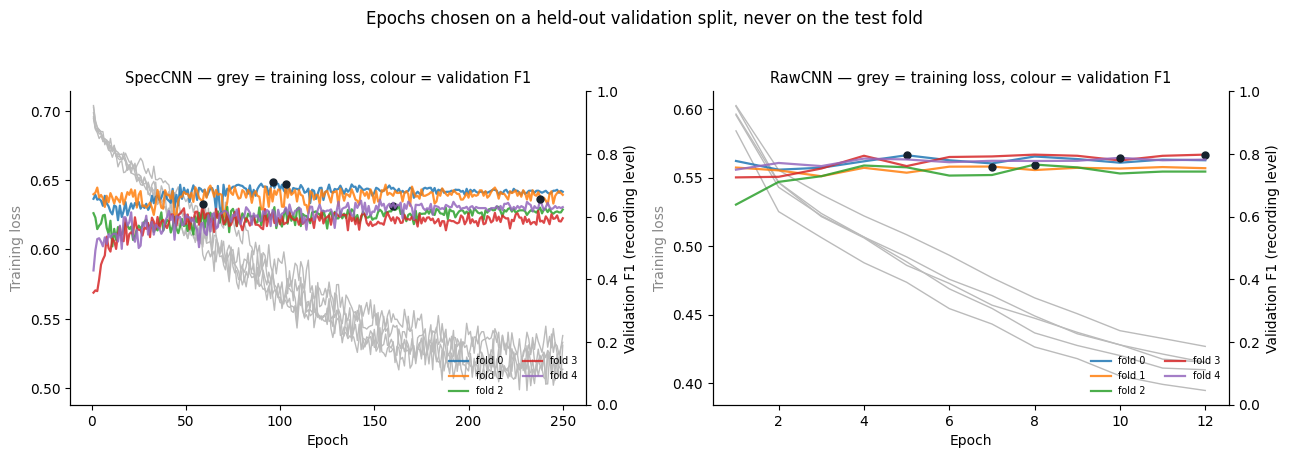

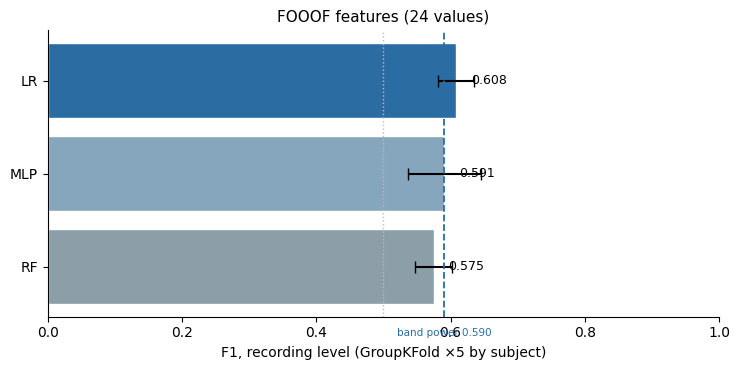

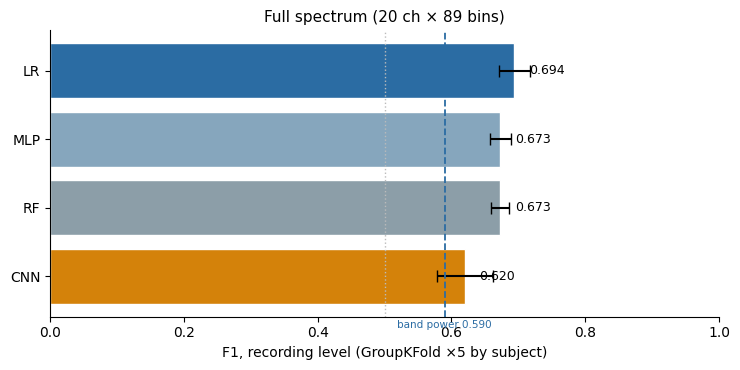

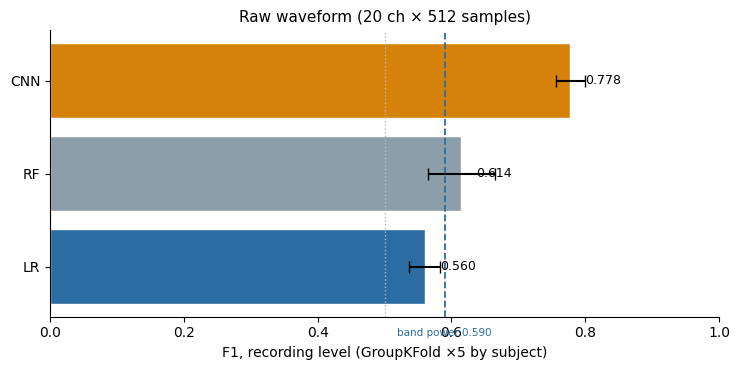

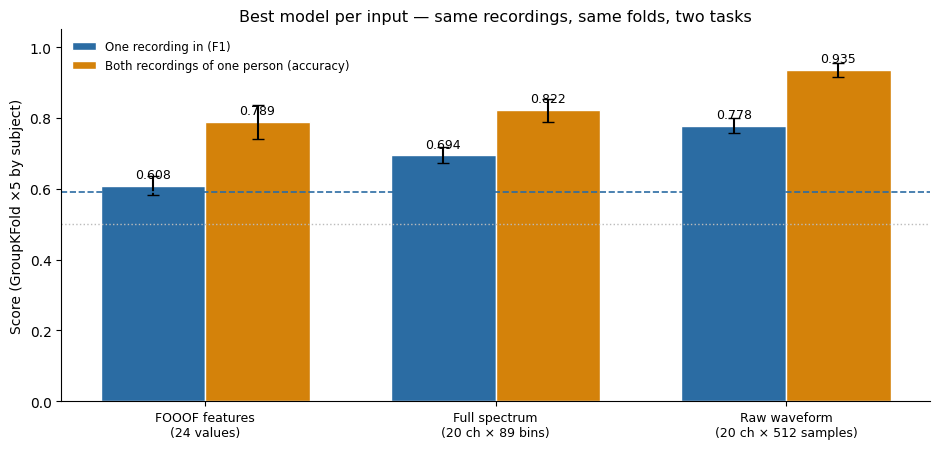

บันทึกรูป: nb5d_curves · nb5d_fooof · nb5d_spectrum · nb5d_raw · nb5d_summary


In [7]:
hist = pd.read_csv('outputs/nb5d_history.csv')
res  = pd.read_csv('outputs/nb5d_matrix.csv')
NAME = {'FOOOF': 'FOOOF features (24 values)',
        'Spectrum': 'Full spectrum (20 ch × 89 bins)',
        'Raw': 'Raw waveform (20 ch × 512 samples)'}
C = {'LR': '#2b6ca3', 'RF': '#8c9ea8', 'MLP': '#86a6bd', 'CNN': '#d4820a'}

# ══ รูป A — เส้นการเรียนรู้รายepoch ══
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, tag in zip(axes, ['SpecCNN', 'RawCNN']):
    h = hist[hist.model == tag]
    if not len(h): continue
    a2 = ax.twinx()
    for k in sorted(h.fold.unique()):
        d = h[h.fold == k]
        ax.plot(d.epoch, d.train_loss, color='#bbb', lw=1)
        a2.plot(d.epoch, d.val_f1, lw=1.6, alpha=.85, label=f'fold {k}')
        best = d.loc[d.val_f1.idxmax()]
        a2.plot(best.epoch, best.val_f1, 'o', ms=5, color='#16222E')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Training loss', color='#888')
    a2.set_ylabel('Validation F1 (recording level)'); a2.set_ylim(0, 1)
    ax.set_title(f'{tag} — grey = training loss, colour = validation F1', fontsize=10.5)
    a2.legend(fontsize=7, ncol=2, frameon=False, loc='lower right')
    for sp in ('top',): ax.spines[sp].set_visible(False); a2.spines[sp].set_visible(False)
fig.suptitle('Epochs chosen on a held-out validation split, never on the test fold',
             fontsize=12, y=1.03)
plt.tight_layout(); plt.savefig('outputs/nb5d_curves.png', dpi=150, bbox_inches='tight'); plt.show()

# ══ รูป B — หนึ่งรูปต่อหนึ่งข้อมูลเข้า ══
for inp in ['FOOOF', 'Spectrum', 'Raw']:
    d = res[res.input == inp].sort_values('f1')
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    bars = ax.barh(d.model, d.f1, xerr=d.sd, color=[C[m] for m in d.model],
                   edgecolor='white', capsize=4)
    for b, v in zip(bars, d.f1):
        ax.text(v + 0.022, b.get_y() + b.get_height()/2, f'{v:.3f}', va='center', fontsize=9)
    ax.axvline(BASE, color='#2b6ca3', ls='--', lw=1.3)
    ax.text(BASE, -0.75, f'band power {BASE:.3f}', fontsize=7.5, color='#2b6ca3', ha='center')
    ax.axvline(0.5, color='#bbb', ls=':', lw=1)
    ax.set_xlim(0, 1); ax.set_xlabel('F1, recording level (GroupKFold ×5 by subject)')
    ax.set_title(NAME[inp], fontsize=11)
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout(); plt.savefig(f'outputs/nb5d_{inp.lower()}.png', dpi=150,
                                    bbox_inches='tight'); plt.show()

# ══ รูป C — สรุปรวม สองโจทย์ ══
pr = pd.read_csv('outputs/nb5d_paired.csv').set_index('input')
best = res.loc[res.groupby('input').f1.idxmax()].set_index('input')
order = ['FOOOF', 'Spectrum', 'Raw']
fig, ax = plt.subplots(figsize=(9.5, 4.6))
x, wd = np.arange(3), 0.36
b1 = ax.bar(x - wd/2, [best.loc[i].f1 for i in order], wd, yerr=[best.loc[i].sd for i in order],
            capsize=4, color='#2b6ca3', edgecolor='white', label='One recording in (F1)')
b2 = ax.bar(x + wd/2, [pr.loc[i].paired_acc for i in order], wd, yerr=[pr.loc[i].sd for i in order],
            capsize=4, color='#d4820a', edgecolor='white', label='Both recordings of one person (accuracy)')
for bb in (b1, b2):
    for b in bb:
        ax.text(b.get_x()+b.get_width()/2, b.get_height()+0.022, f'{b.get_height():.3f}',
                ha='center', fontsize=9)
ax.axhline(BASE, color='#2b6ca3', ls='--', lw=1.2)
ax.axhline(0.5, color='#bbb', ls=':', lw=1)
ax.set_xticks(x); ax.set_xticklabels([NAME[i].replace(' (', '\n(') for i in order], fontsize=9)
ax.set_ylim(0, 1.05); ax.set_ylabel('Score (GroupKFold ×5 by subject)')
ax.set_title('Best model per input — same recordings, same folds, two tasks', fontsize=11.5)
ax.legend(fontsize=8.5, frameon=False); ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.savefig('outputs/nb5d_summary.png', dpi=150, bbox_inches='tight'); plt.show()
print("บันทึกรูป: nb5d_curves · nb5d_fooof · nb5d_spectrum · nb5d_raw · nb5d_summary")

## สรุป

เมื่อใช้โจทย์ ไฟล์ และ fold ชุดเดียวกัน **ความต่างของคะแนนมาจากข้อมูลเข้ามากกว่าโมเดล**
บนข้อมูลสองแบบแรก LR, RF และ MLP ต่างกันไม่เกินราว 0.03 แต่การเปลี่ยนจาก
FOOOF (0.608) เป็นสเปกตรัมเต็ม (0.694) เพิ่ม 0.09 และเป็นรูปคลื่นที่ใช้ CNN (0.778)
เพิ่มอีก 0.08

**โครงข่ายไม่ได้ช่วยทุกกรณี** CNN บนสเปกตรัม (0.620) ต่ำกว่า LR บนข้อมูลเดียวกัน
แต่รูปคลื่นกลับต้องใช้ CNN เท่านั้น LR กับ RF บนรูปคลื่นได้แค่ 0.56–0.61 ใกล้เส้นฐาน
band power ข้อมูลที่ช่วยแยกจึงอยู่ในรูปร่างของคลื่นตามเวลา ซึ่งต้องใช้ convolution
ถึงจะดึงออกมาได้

**โจทย์จับคู่** ใช้โมเดลชุดเดิม เอาคะแนนของสองไฟล์ของคนเดียวกันมาเทียบ ได้
FOOOF 0.789 · สเปกตรัม 0.822 · รูปคลื่น + CNN 0.935 ถ้าดูเฉพาะคู่ที่ ICA ลบ component
เท่ากัน คะแนนไม่ลดลง (0.953) จึงไม่ได้มาจากปริมาณสิ่งแปลกปลอม · FOOOF ดีขึ้นมากเมื่อมี
baseline ของคนเดียวกันให้เทียบ (0.61 → 0.79) สอดคล้องกับที่พบว่าแต่ละคนต่างกันมาก

**ข้อจำกัด** ฝั่ง FOOOF สกัดที่ 250 Hz จากทั้งไฟล์ ส่วนฝั่งรูปคลื่นใช้ 128 Hz และ
z-score ทีละหน้าต่าง จึงไม่ได้มาจากตัวอย่างเดียวกันเป๊ะ · ค่าตั้งของ CNN บนสเปกตรัม
ถูกปรับหนึ่งรอบหลังเห็นผลรอบแรก · CNN บนรูปคลื่นได้ 0.778 ที่นี่ และ 0.792 ใน NB5a
เพราะใช้ fold และวิธีเลือก epoch ต่างกัน